# 05 · Curves Becoming Graphs

**Arithmetic Without Addition Lab**  |  Nodal degeneration, normalization and conservation of genus

---

## How a loop can remember a handle

The family
$$E_t:\quad y^2=x(x-1)(x-t)$$
consists of smooth elliptic curves for $t\ne0,1$ (over $\mathbb C$). At $t=0$ it becomes the nodal cubic $y^2=x^2(x-1)$. The normalization of this singular cubic has genus $0$; yet its **arithmetic genus** remains $1$. The missing unit is recovered by the first Betti number of its dual graph—a single vertex with a loop.

For a connected nodal curve $C$ with components $C_i$ and dual graph $\Gamma$,
$$p_a(C)=\sum_i g(\widetilde{C_i})+b_1(\Gamma).$$
This is the cleanest sense in which a cycle in a graph can remember a handle of a Riemann surface.

In [1]:
import sympy as sp
import matplotlib.pyplot as plt
import networkx as nx
from awa_lab.stable_curves import discriminant_legendre, nodal_parameterization, arithmetic_genus_dual_graph
x,y,t=sp.symbols('x y t')
print('Discriminant of x(x-1)(x-t):',discriminant_legendre())
print('Parameterization of the nodal cubic:',nodal_parameterization())
assert sp.factor(discriminant_legendre())==t**2*(t-1)**2
f=y**2-x**2*(x-1)
print('Singular at the origin:',[a.subs({x:0,y:0}) for a in [f,sp.diff(f,x),sp.diff(f,y)]])
assert all(a.subs({x:0,y:0})==0 for a in [f,sp.diff(f,x),sp.diff(f,y)])

Discriminant of x(x-1)(x-t): t**2*(t - 1)**2
Parameterization of the nodal cubic: (u**2 + 1, u*(u**2 + 1), 0)
Singular at the origin: [0, 0, 0]


## Experiment B · Compute dual-graph genus

A nodal irreducible cubic has one component and one node: the dual graph has one vertex and one loop. Two projective lines glued at **two distinct nodes** have two vertices and two parallel edges. Each graph has first Betti number one, so both connected nodal curves have arithmetic genus one, although their normalizations have genus zero.

A tree of rational components, by contrast, has $b_1=0$ and arithmetic genus zero.

In [2]:
examples = {
    'irreducible nodal cubic':([0],[(0,0)]),
    'two rational components, two nodes':([0,0],[(0,1),(0,1)]),
    'three rational components, a tree':([0,0,0],[(0,1),(1,2)]),
    'elliptic component attached to a line':([1,0],[(0,1)])}
for label,(genera,edges) in examples.items():
    data=arithmetic_genus_dual_graph(genera,edges)
    print(f'{label}: b1={data["graph_betti_1"]}, arithmetic genus={data["arithmetic_genus"]}')
assert arithmetic_genus_dual_graph([0],[(0,0)])['arithmetic_genus']==1

irreducible nodal cubic: b1=1, arithmetic genus=1
two rational components, two nodes: b1=1, arithmetic genus=1
three rational components, a tree: b1=0, arithmetic genus=0
elliptic component attached to a line: b1=0, arithmetic genus=1


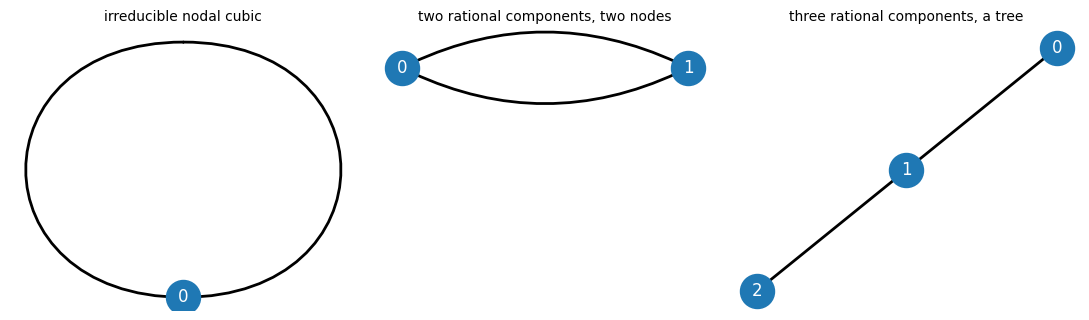

In [3]:
fig,axes=plt.subplots(1,3,figsize=(11,3.3))
for ax, (title,(genera,edges)) in zip(axes,list(examples.items())[:3]):
    G=arithmetic_genus_dual_graph(genera,edges)['graph']
    if len(G)==1: pos={0:(0,0)}
    elif len(G)==2: pos={0:(-1,0),1:(1,0)}
    else: pos=nx.spring_layout(G,seed=4)
    nx.draw_networkx_nodes(G,pos,ax=ax,node_size=600)
    nx.draw_networkx_labels(G,pos,ax=ax,font_color='white')
    edge_list=list(G.edges(keys=True))
    for ix,(a,b,key) in enumerate(edge_list):
        rad=0.5 if a==b else (0.25 if len(edge_list)>1 and G.number_of_edges(a,b)>1 and ix%2==0 else -0.25 if G.number_of_edges(a,b)>1 else 0)
        nx.draw_networkx_edges(G,pos,ax=ax,edgelist=[(a,b)],connectionstyle=f'arc3,rad={rad}',width=2)
    ax.set_title(title,fontsize=10);ax.axis('off')
plt.tight_layout();plt.show()

## The hypothesis matters

The genus formula above is for **nodal** connected curves, not arbitrary singular degenerations. For other singularities, correction terms involve their delta invariants; for disconnected curves, the Betti-number formula must be adjusted.

### Investigate

1. A nodal curve has normalized components of genera $2,1,0$ and a dual graph with four edges and three vertices. Assuming it is connected, compute its arithmetic genus.
2. Find parameter values at which the Legendre family is singular by computing the cubic discriminant. Explain why the discriminant vanishes to order two at $t=0$ and $t=1$.
3. Verify directly that the rational parameterization of the nodal fiber identifies **two distinct** points above the node.
4. What changes in this analysis if the limiting curve has a cusp instead of a node?